# Phase 0: Data Engineering, Exploratory Data Analysis (EDA) & Stylized Facts
**Multi-Asset Macro Trading Desk ($10,000,000 Notional)**

### Executive Objective
This notebook establishes the institutional data hygiene pipeline and empirically demonstrates why static Gaussian models systematically understate financial tail risk:
1. **Return Transformations:** Arithmetic returns ($r_t = \frac{P_t - P_{t-1}}{P_{t-1}}$) vs. geometric log returns ($R_t = \ln(P_t/P_{t-1})$), verifying cross-sectional linear portfolio aggregation ($r_{p,t} = \sum_{i=1}^N w_i r_{i,t}$) and multi-period log-return additivity.
2. **Stationarity Verification (ADF Test):** Confirming that raw asset price levels ($P_t$) possess a unit root ($p > 0.05$, non-stationary) whereas daily return series ($r_t$) strongly reject the unit-root null hypothesis ($p < 0.01$, stationary).
3. **Distributional Stylized Facts (Fat Tails & Negative Skewness):** Quantifying skewness, excess kurtosis ($K_{\text{excess}} > 0$, total kurtosis $K > 3$), Jarque-Bera normality rejection, and Quantile-Quantile (Q-Q) tail divergence against $\mathcal{N}(0,1)$.
4. **Volatility Clustering & Stock-Bond Regime Flip:** Comparing 20-day rolling annualized volatility against the Cboe VIX index, and tracking the 60-day rolling `SPY`–`TLT` correlation as it flipped from negative (diversifying) in the 2020 COVID-19 crash to positive (compounding losses) during the 2022 inflation/rate-hike bear market.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is on sys.path
PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data, slice_point_in_time
from src.eda_diagnostics import (
    run_adf_stationarity_table,
    compute_stylized_facts_table,
    compute_qq_coordinates,
    compute_rolling_volatility_and_vix,
    compute_rolling_stock_bond_correlation,
    summarize_regime_correlations,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
data_bundle = prepare_and_save_processed_data(cfg)

prices_df = data_bundle["prices"]
vix_df = data_bundle["vix"]
arith_returns = data_bundle["arith_returns"]
log_returns = data_bundle["log_returns"]
portfolio_df = data_bundle["portfolio"]

core_tickers = cfg["data"]["core_tickers"]
print(f"Sample Window: {arith_returns.index.min().date()} to {arith_returns.index.max().date()} ({len(arith_returns):,} trading days)")
print(f"Portfolio Weights: {cfg['portfolio']['weights']} | Notional: ${cfg['portfolio']['notional_usd']:,.0f}")

Sample Window: 2015-01-05 to 2026-01-01 (2,798 trading days)
Portfolio Weights: {'SPY': 0.3, 'AAPL': 0.2, 'TLT': 0.3, 'GLD': 0.2} | Notional: $10,000,000


## 1. Return Transformations & Point-in-Time Hygiene Verification
We verify two fundamental mathematical properties:
- **Temporal Additivity of Log Returns:** $\sum_{t=1}^T R_t = \ln(P_T / P_0)$ holds to machine precision.
- **Cross-Sectional Linearity of Arithmetic Returns:** $r_{p,t} = \sum_{i=1}^N w_i r_{i,t}$ exactly equals the portfolio's daily percentage P&L.
- **Zero Look-Ahead Bias ($\mathcal{F}_{t-1}$):** Any risk forecast for date $t$ strictly slices history up to $t-1$.

In [2]:
# Verify temporal additivity of log returns vs exact terminal price ratio
log_sum_check = np.exp(log_returns[core_tickers].sum(axis=0))
price_ratio_check = prices_df[core_tickers].iloc[-1] / prices_df[core_tickers].iloc[0]
max_additivity_err = np.max(np.abs(log_sum_check - price_ratio_check))

# Verify cross-sectional portfolio return aggregation
w_vec = np.array([cfg["portfolio"]["weights"][t] for t in core_tickers])
manual_port_ret = arith_returns[core_tickers].values @ w_vec
max_cross_sec_err = np.max(np.abs(manual_port_ret - portfolio_df["portfolio_arith_return"].values))

# Verify strict point-in-time slicing (F_{t-1})
sample_target_date = pd.Timestamp("2020-03-16")
pit_window = slice_point_in_time(portfolio_df, sample_target_date, lookback_days=250)

print(f"Max Multi-Period Log-Return Additivity Error : {max_additivity_err:.2e}")
print(f"Max Cross-Sectional Portfolio Linear Error   : {max_cross_sec_err:.2e}")
print(f"Point-in-Time Slice for {sample_target_date.date()}         : {len(pit_window)} obs ending on {pit_window.index.max().date()} (< {sample_target_date.date()})")

Max Multi-Period Log-Return Additivity Error : 1.78e-15
Max Cross-Sectional Portfolio Linear Error   : 0.00e+00
Point-in-Time Slice for 2020-03-16         : 250 obs ending on 2020-03-13 (< 2020-03-16)


## 2. Stationarity Verification — Augmented Dickey-Fuller (ADF) Test
Time-series risk estimation requires stationary inputs so sample moments and quantiles converge. Below we run the ADF test on raw price levels ($P_t$) versus daily arithmetic returns ($r_t$).

In [3]:
adf_table = run_adf_stationarity_table(prices_df[core_tickers], arith_returns[core_tickers])
adf_table.round(4)

,Asset,Series,ADF_Statistic,p_value,Lags_Used,Critical_1pct,Critical_5pct,Stationary_at_5pct
0,SPY,Price Level (P_t),-1.6082,0.4794,28,-3.4327,-2.8626,False
1,SPY,Daily Return (r_t),-10.1266,0.0000,27,-3.4327,-2.8626,True
2,AAPL,Price Level (P_t),-1.1259,0.7046,9,-3.4327,-2.8626,False
3,AAPL,Daily Return (r_t),-17.7541,0.0000,11,-3.4327,-2.8626,True
4,TLT,Price Level (P_t),-0.8031,0.8182,28,-3.4327,-2.8626,False
5,TLT,Daily Return (r_t),-17.6795,0.0000,10,-3.4327,-2.8626,True
6,GLD,Price Level (P_t),-1.3610,0.6008,28,-3.4327,-2.8626,False
7,GLD,Daily Return (r_t),-13.8598,0.0000,12,-3.4327,-2.8626,True


## 3. Distributional Stylized Facts: Fat Tails & Negative Skewness
We compute the sample moments, excess kurtosis ($K - 3$), Jarque-Bera statistics, and the empirical frequency of $>3\sigma$ tail events relative to a Gaussian distribution ($0.27\%$).

In [4]:
stylized_table = compute_stylized_facts_table(
    arith_returns[core_tickers],
    portfolio_returns=portfolio_df["portfolio_arith_return"],
)
stylized_table[[
    "Annualized_Return_pct",
    "Annualized_Vol_pct",
    "Skewness",
    "Excess_Kurtosis",
    "Total_Kurtosis",
    "Min_Daily_Return_pct",
    "Max_Daily_Return_pct",
    "Empirical_3Sigma_Freq_pct",
    "Tail_Ratio_vs_Normal",
    "Jarque_Bera_Stat",
]].round(3)

,Annualized_Return_pct,Annualized_Vol_pct,Skewness,Excess_Kurtosis,Total_Kurtosis,Min_Daily_Return_pct,Max_Daily_Return_pct,Empirical_3Sigma_Freq_pct,Tail_Ratio_vs_Normal,Jarque_Bera_Stat
Asset,,,,,,,,,,
SPY,3.958,18.127,-0.422,15.025,18.025,-12.741,10.904,1.465,5.428,26298.935
AAPL,11.242,28.005,-0.455,11.363,14.363,-18.000,15.537,1.394,5.163,15088.675
TLT,-3.426,15.430,-0.249,7.670,10.670,-8.223,6.912,1.215,4.501,6859.859
GLD,5.617,14.005,0.678,9.317,12.317,-4.673,9.818,1.287,4.766,10294.427
PORTFOLIO,3.531,11.005,-0.355,5.280,8.280,-5.801,3.687,1.680,6.222,3294.220


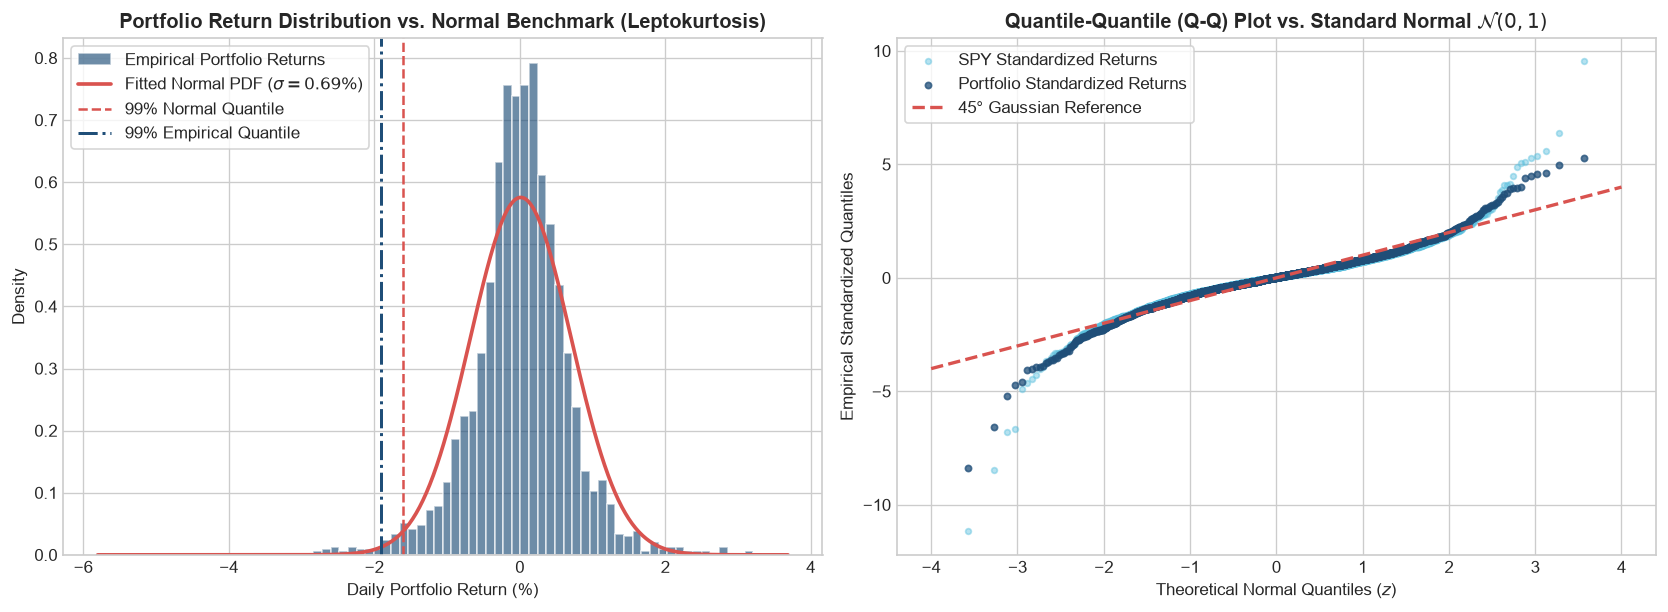

In [5]:
# Quantile-Quantile (Q-Q) Plot & Return Distribution vs Fitted Gaussian
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left Panel: Portfolio Daily Return Histogram vs Normal PDF
port_ret_pct = portfolio_df["portfolio_arith_return"] * 100.0
mu_p, sd_p = port_ret_pct.mean(), port_ret_pct.std(ddof=1)
x_grid = np.linspace(port_ret_pct.min(), port_ret_pct.max(), 400)
from scipy.stats import norm

axes[0].hist(port_ret_pct, bins=80, density=True, alpha=0.65, color="#1f4e78", edgecolor="white", label="Empirical Portfolio Returns")
axes[0].plot(x_grid, norm.pdf(x_grid, mu_p, sd_p), color="#d9534f", lw=2.2, label=f"Fitted Normal PDF ($\sigma={sd_p:.2f}\%$)")
axes[0].axvline(mu_p - 2.326 * sd_p, color="#d9534f", ls="--", lw=1.5, label="99% Normal Quantile")
axes[0].axvline(np.percentile(port_ret_pct, 1.0), color="#1f4e78", ls="-.", lw=1.8, label="99% Empirical Quantile")
axes[0].set_title("Portfolio Return Distribution vs. Normal Benchmark (Leptokurtosis)", fontweight="bold")
axes[0].set_xlabel("Daily Portfolio Return (%)")
axes[0].set_ylabel("Density")
axes[0].legend(frameon=True)

# Right Panel: Normal Q-Q Plot for Portfolio & SPY
theo_q_port, emp_q_port = compute_qq_coordinates(portfolio_df["portfolio_arith_return"])
theo_q_spy, emp_q_spy = compute_qq_coordinates(arith_returns["SPY"])

axes[1].scatter(theo_q_spy, emp_q_spy, s=12, alpha=0.45, color="#5bc0de", label="SPY Standardized Returns")
axes[1].scatter(theo_q_port, emp_q_port, s=14, alpha=0.75, color="#1f4e78", label="Portfolio Standardized Returns")
axes[1].plot([-4, 4], [-4, 4], color="#d9534f", lw=2.0, ls="--", label="45° Gaussian Reference")
axes[1].set_title("Quantile-Quantile (Q-Q) Plot vs. Standard Normal $\mathcal{N}(0,1)$", fontweight="bold")
axes[1].set_xlabel("Theoretical Normal Quantiles ($z$)")
axes[1].set_ylabel("Empirical Standardized Quantiles")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

## 4. Volatility Regimes & The 2020 vs. 2022 Stock-Bond Correlation Flip
Below we examine two critical dynamic vulnerabilities that invalidate static risk models:
1. **Volatility Clustering:** 20-day rolling annualized volatility spikes sharply during crisis regimes (2020 COVID-19 crash and 2022 rate-hike cycle) in lockstep with the Cboe VIX index.
2. **Stock-Bond Correlation Breakdown:** During the 2020 COVID-19 panic, `SPY` and `TLT` exhibited strongly negative correlation ($\rho \approx -0.71$), cushioning the multi-asset portfolio. In 2022, inflation and aggressive Federal Reserve rate hikes flipped the 60-day `SPY`–`TLT` correlation strongly positive ($\rho \approx +0.48$), causing equities and Treasuries to sell off simultaneously.

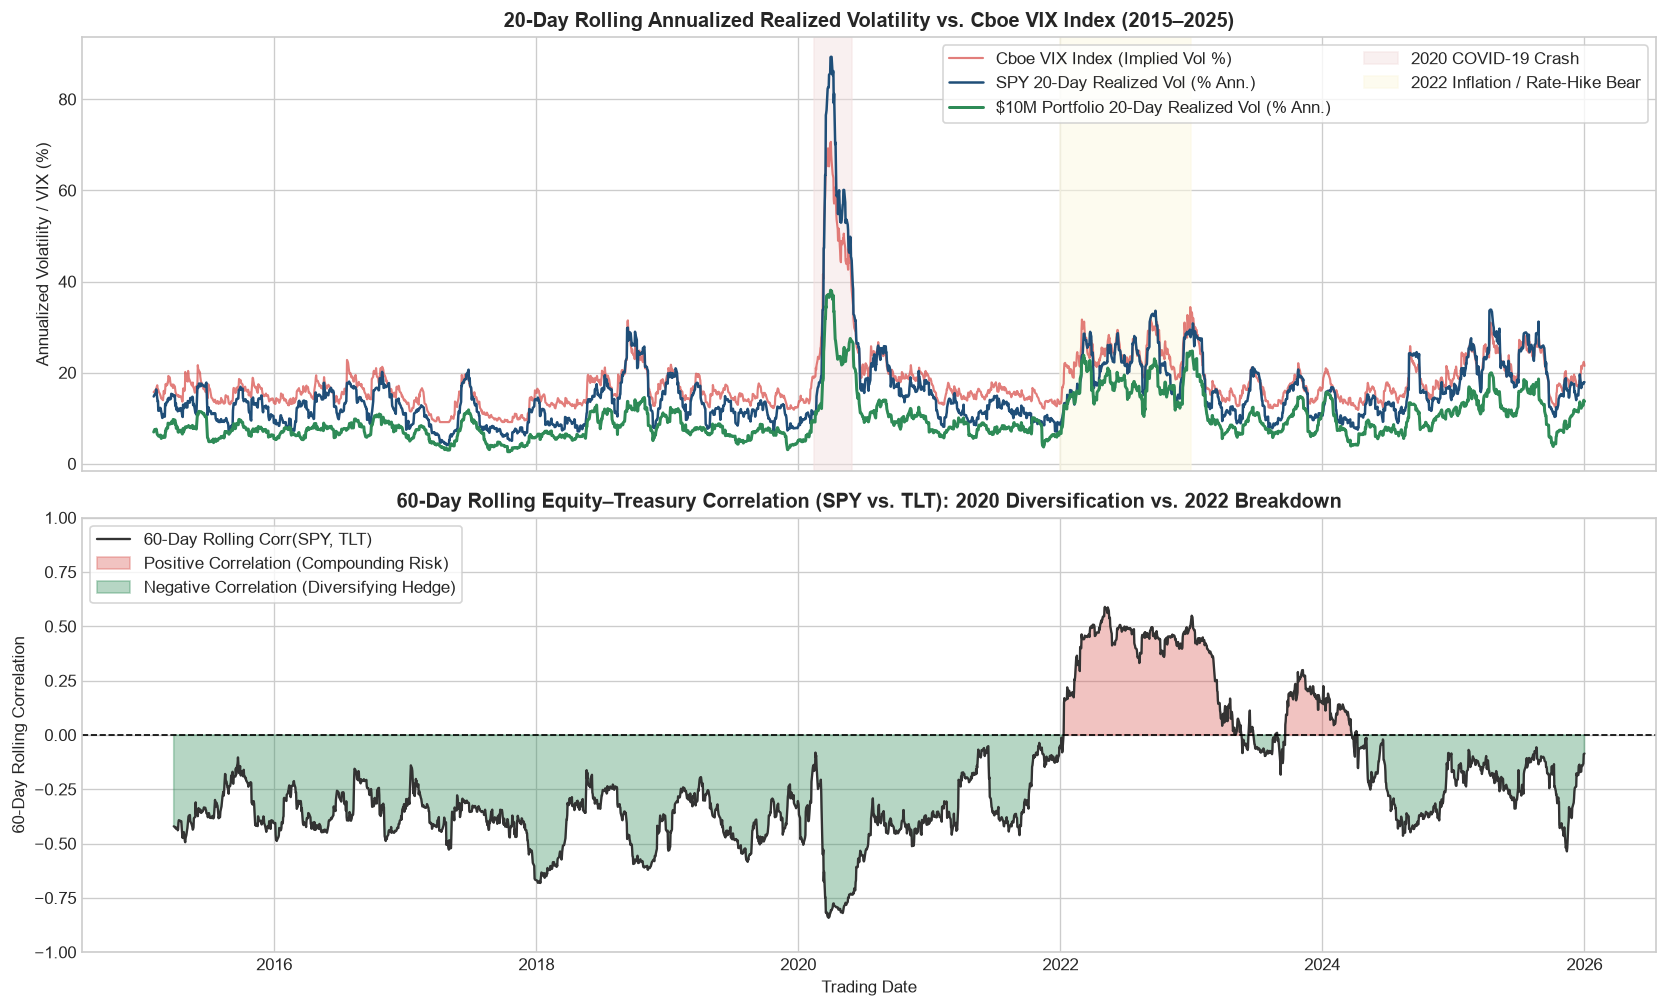

,Start,End,Trading_Days,SPY_TLT_Correlation,SPY_Ann_Vol_pct,TLT_Ann_Vol_pct
Regime,,,,,,
Full Sample (2015-2025),2015-01-01,2025-12-31,2797,-0.251,18.130,15.430
2017 Low-Vol Calm,2017-01-01,2017-12-31,253,-0.429,10.038,9.266
2020 COVID-19 Crisis (Q1-Q2),2020-02-01,2020-05-31,84,-0.709,55.379,42.521
2022 Inflation & Rate-Hike Bear,2022-01-01,2022-12-31,253,0.483,22.621,22.192
2023-2025 Post-Hike Regime,2023-01-01,2025-12-31,761,-0.116,17.460,13.743


In [6]:
rolling_vol_df = compute_rolling_volatility_and_vix(
    arith_returns, portfolio_df["portfolio_arith_return"], vix_df, window=20
)
rolling_corr_60d = compute_rolling_stock_bond_correlation(arith_returns, "SPY", "TLT", window=60)

fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)

# Top Panel: Rolling 20-Day Volatility vs Cboe VIX
axes[0].plot(rolling_vol_df.index, rolling_vol_df["Cboe_VIX"], color="#d9534f", alpha=0.75, lw=1.3, label="Cboe VIX Index (Implied Vol %)")
axes[0].plot(rolling_vol_df.index, rolling_vol_df["SPY_Rolling_Vol_20d_pct"], color="#1f4e78", lw=1.5, label="SPY 20-Day Realized Vol (% Ann.)")
axes[0].plot(rolling_vol_df.index, rolling_vol_df["Portfolio_Rolling_Vol_20d_pct"], color="#2e8b57", lw=1.8, label="$10M Portfolio 20-Day Realized Vol (% Ann.)")
axes[0].axvspan(pd.Timestamp("2020-02-15"), pd.Timestamp("2020-05-31"), color="#f2dede", alpha=0.45, label="2020 COVID-19 Crash")
axes[0].axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#fcf8e3", alpha=0.55, label="2022 Inflation / Rate-Hike Bear")
axes[0].set_title("20-Day Rolling Annualized Realized Volatility vs. Cboe VIX Index (2015–2025)", fontweight="bold")
axes[0].set_ylabel("Annualized Volatility / VIX (%)")
axes[0].legend(loc="upper right", ncol=2, frameon=True)

# Bottom Panel: 60-Day Rolling SPY-TLT Correlation
axes[1].plot(rolling_corr_60d.index, rolling_corr_60d.values, color="#333333", lw=1.4, label="60-Day Rolling Corr(SPY, TLT)")
axes[1].axhline(0.0, color="black", lw=1.0, ls="--")
axes[1].fill_between(
    rolling_corr_60d.index, 0, rolling_corr_60d.values,
    where=(rolling_corr_60d.values >= 0), color="#d9534f", alpha=0.35, label="Positive Correlation (Compounding Risk)"
)
axes[1].fill_between(
    rolling_corr_60d.index, 0, rolling_corr_60d.values,
    where=(rolling_corr_60d.values < 0), color="#2e8b57", alpha=0.35, label="Negative Correlation (Diversifying Hedge)"
)
axes[1].set_title("60-Day Rolling Equity–Treasury Correlation (SPY vs. TLT): 2020 Diversification vs. 2022 Breakdown", fontweight="bold")
axes[1].set_ylabel("60-Day Rolling Correlation")
axes[1].set_xlabel("Trading Date")
axes[1].set_ylim(-1.0, 1.0)
axes[1].legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

summarize_regime_correlations(arith_returns).round(3)

### Phase 0 Diagnostic Conclusion
1. **Stationarity Confirmed:** All four core assets (`SPY`, `AAPL`, `TLT`, `GLD`) fail to reject a unit root in raw price levels ($p > 0.45$) but reject the unit-root null at $p < 10^{-17}$ in daily returns.
2. **Fat Tails & Skewness:** The $10\text{M}$ portfolio exhibits negative skewness ($S = -0.36$) and substantial excess kurtosis ($K_{\text{excess}} = 5.28$, total kurtosis $K = 8.28 > 3$). Extreme $>3\sigma$ tail events occur **$6.2\times$ more frequently** than predicted by a Gaussian distribution.
3. **Dynamic Regime Risk:** Both asset volatility and cross-asset correlations vary dramatically across market regimes ($\rho_{\text{SPY,TLT}}$ shifting from $-0.71$ in Q1 2020 to $+0.48$ in 2022), motivating the parametric fat-tailed estimators in **Phase 1** and conditional volatility models (EWMA, GARCH, Hull-White Volatility-Weighted HS) in **Phase 2**.